# Gotthard / VLS diagnostics

Inspect single-shot spectra, their intensity and spectral moments, and the mean spectrum as a function of nominal incident photon energy. The notebook can read raw FLASH files directly, without local DAQ or SDU data, or use existing combined H5 files for the spectra.

Set the run numbers and detector parameters below, then run the cells in order. The energy scan uses the raw H5 wavelength settings of the primary run (`RUN`), even when spectra are loaded from a combined file. All spectra are in background-subtracted ADU unless stated otherwise. The pixel axis is not calibrated in eV.

The main result is in section 3. The later sections are diagnostic; Gaussian fitting and the offset scan are optional.

The raw Gotthard lines are retained during loading so that the first two background frames can be subtracted before matching the remaining lines to GMD bunches.

In [2]:
# ---- Imports and paths ------------------------------------------------------
from pathlib import Path
import sys

import h5py
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

# Repo root = the first folder above the working directory that holds analysis/scripts/config.py
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / "analysis" / "scripts" / "config.py").exists())
sys.path.insert(0, str(REPO_ROOT / "analysis" / "scripts"))
import config
import data_loading
import processing

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
TRAIN_RATE_HZ = 10

In [3]:
# ---- Parameters ---------------------------------------------------------------
RUNS = [60545]               # Add runs for comparison; first run is used for the energy scan
RUN = RUNS[0]

COMBINED_H5 = None           # None = raw files; filename for one run, or dict keyed by run
RAW_DIR = Path("/asap3/flash/gpfs/fl24/2026/data/11024642/raw")
TRAIN_STEP = 20              # Every N-th train (VLS ~0.5 MB per train)
MAX_FILES = None             # Raw mode: first N files only
VLS_OFFSET = 2               # Raw Gotthard line b + offset -> GMD bunch b
COMBINED_VLS_OFFSET = None   # Set to 0 only if the combined file contains unshifted lines
BUNCH_RANGE = None           # (start, stop); None = automatically select slots with GMD pulses

VLS_ROI = (300, 640)         # Pixel range (half-open)
VLS_BG_PIXELS = (650, 800)    # Signal-free pixels for common-mode subtraction
VLS_BAD_PIXELS = [0, 1, 679, 680, 681, *range(832, 864)]
MOMENT_THRESHOLD = None     # ADU; None = original spectral moments
N_BG = 2                    # First raw Gotthard lines used as background; 0 = disable
CHUNK_TRAINS = 100          # Background subtraction in blocks
COMPLETE_TRAINS_ONLY = True # Keep the most common number of matched shots per train

# Incident photon-energy scan
ENERGY_MIN = 265
ENERGY_MAX = 282
ENERGY_STEP = 0.5
ENERGY_TOL = 0.15             # Accept nominal energies within +/- tolerance of each step

# Filters for the binned spectra and moment checks only (section 5)
FILTERS = {"gmd": None, "vls_sum": None, "com": None, "width": None, "t_min": None}
BIN_ON = "gmd"
N_BINS = 8
BIN_PERCENTILES = (2, 98)
BIN_EDGES = None
NORMALISE = None             # None: mean ADU | "gmd": sum/sum(GMD) | "area": unit area

# Display settings for individual spectra and run comparison
VIEW_NORMALISE = None        # None: raw intensity | "peak" | "area"

## 1. Load and process the spectra

Load with zero offset to retain the raw detector lines. Run 60545 gave a best offset of +2 (Pearson r = 0.946 in the saved alignment scan): raw line 2 corresponds to GMD bunch 0. The first two raw lines (0 and 1) are background, not the first two aligned GMD bunches.

Subtract the dark pedestal and per-frame common mode as before. Then subtract the mean of the first `N_BG` processed raw spectra separately for each train, pixel by pixel. Match signal lines to GMD using `VLS_OFFSET`. By default, discard trains without both background frames or with a non-modal number of matched signal shots. Recalculate integrated intensity, COM and width after subtraction.

`runs[run_no]` contains the corrected spectra (`S`), matched per-shot quantities (`shots`) and small train diagnostics (`train_diag`). `S`, `shots` and `px_roi` refer to the primary run. Raw lines and aligned bunch indices are both retained. Set `N_BG = 0` for a comparison without the train-wise background correction.

In [4]:
def load_run(run_no):
    h5_file = COMBINED_H5.get(run_no) if isinstance(COMBINED_H5, dict) else COMBINED_H5

    if COMBINED_H5 is not None and not isinstance(COMBINED_H5, dict) and len(RUNS) > 1:
        raise ValueError("Use a dict of combined filenames for several runs")

    if h5_file is None:
        data = data_loading.load_raw_h5(run_no, config=1, train_step=TRAIN_STEP,
                                        max_files=MAX_FILES, vls_offset=0)
        source = f"run {run_no} (every {TRAIN_STEP}. train)"
    else:
        if COMBINED_VLS_OFFSET != 0:
            raise ValueError("Combined files must contain unshifted Gotthard lines; set COMBINED_VLS_OFFSET = 0 only after checking")
        h5_path = Path(h5_file)
        if not h5_path.is_absolute():
            h5_path = config.COMBINED_DIR / h5_path
        data = data_loading.load_data(str(h5_path), config=1, downsample_N=TRAIN_STEP)
        source = f"{h5_path.name} (every {TRAIN_STEP}. train)"

    return data, source

In [5]:
def process_run(data):
    gmd = data.gmd
    mpe = data.mpe
    vls = data.vls
    if vls is None:
        raise ValueError("No Gotthard data in this run")
    assert vls.shape[:2] == gmd.shape
    assert 0 <= VLS_ROI[0] < VLS_ROI[1] <= vls.shape[-1]
    assert 0 <= VLS_BG_PIXELS[0] < VLS_BG_PIXELS[1] <= vls.shape[-1]
    assert VLS_ROI[1] <= VLS_BG_PIXELS[0] or VLS_BG_PIXELS[1] <= VLS_ROI[0]

    vls[..., VLS_BAD_PIXELS] = np.nan
    train_ids = np.asarray(data.tID)
    assert train_ids.shape == (len(gmd),) and np.isfinite(train_ids).all()
    assert np.all(train_ids == train_ids.astype(np.int64))
    train_ids = train_ids.astype(np.int64)
    t_min = (train_ids - train_ids[0]) / TRAIN_RATE_HZ / 60

    # Match raw Gotthard lines to GMD bunches
    pulse = np.isfinite(gmd)
    has_frame = np.isfinite(vls[:, :, VLS_BG_PIXELS[0]])
    offset = config.VLS_OFFSET if VLS_OFFSET is None else VLS_OFFSET
    bunches = np.arange(gmd.shape[1])
    lines = bunches + offset
    valid = (lines >= 0) & (lines < vls.shape[1])
    bunches, lines = bunches[valid], lines[valid]

    if BUNCH_RANGE is None:
        lit_slots = np.flatnonzero(pulse.mean(axis=0) > 0.5)
        if not len(lit_slots):
            raise ValueError("No populated bunch slots found; check GMD or set BUNCH_RANGE")
        bunch_range = (int(lit_slots[0]), int(lit_slots[-1]) + 1)
    else:
        bunch_range = BUNCH_RANGE
    assert 0 <= bunch_range[0] < bunch_range[1] <= gmd.shape[1]
    assert 0 <= N_BG < vls.shape[1] and CHUNK_TRAINS > 0

    # Pedestal from raw frames without a matched GMD pulse
    raw_pulse = np.zeros_like(has_frame)
    raw_pulse[:, lines] = pulse[:, bunches]
    dark = has_frame & ~raw_pulse
    pedestal = np.zeros(vls.shape[-1])
    if dark.sum() > 100:
        for b in np.flatnonzero(dark.any(axis=0)):
            pedestal += vls[dark[:, b], b].sum(axis=0)
        pedestal /= dark.sum()
    else:
        print("WARNING: <= 100 dark frames, common mode only")

    def subtract_cm(t, b):
        bg = vls[t, b, slice(*VLS_BG_PIXELS)] - pedestal[slice(*VLS_BG_PIXELS)]
        cm = np.nanmedian(bg, axis=-1)
        spec = vls[t, b, slice(*VLS_ROI)] - pedestal[slice(*VLS_ROI)] - cm[..., None]
        return np.nan_to_num(spec)

    # Select signal frames (never use background lines as signal)
    m = (bunches >= bunch_range[0]) & (bunches < bunch_range[1]) & (lines >= N_BG)
    bunches, lines = bunches[m], lines[m]
    shot = pulse[:, bunches] & has_frame[:, lines]
    n_per_train = shot.sum(axis=1)
    good_bg = has_frame[:, :N_BG].all(axis=1)
    good_train = good_bg & (n_per_train > 0)
    if not good_train.any():
        raise ValueError("No trains with valid background and matched signal frames")
    lengths, frequency = np.unique(n_per_train[good_train], return_counts=True)
    n_bunches = lengths[np.argmax(frequency)]
    if COMPLETE_TRAINS_ONLY:
        good_train &= n_per_train == n_bunches
    shot[~good_train] = False
    train_idx, j = np.nonzero(shot)
    slot_idx, line_idx = bunches[j], lines[j]

    # Background spectrum and signal spectra, processed in train blocks
    S_run = np.empty((len(train_idx), len(px_roi)), dtype=np.float32)
    before = np.empty(len(train_idx))
    diag_shape = (len(gmd), vls.shape[1])
    vls_before = np.full(diag_shape, np.nan)
    vls_after = np.full(diag_shape, np.nan)
    gmd_train = np.full(diag_shape, np.nan)
    for start in range(0, len(gmd), CHUNK_TRAINS):
        stop = min(start + CHUNK_TRAINS, len(gmd))
        tt = np.arange(start, stop)
        tt = tt[good_train[tt]]
        if not len(tt):
            continue
        if N_BG:
            bg_spec = subtract_cm(tt[:, None], np.arange(N_BG)[None, :])
            background = bg_spec.mean(axis=1)
            vls_before[tt, :N_BG] = bg_spec.sum(axis=-1)
            vls_after[tt, :N_BG] = (bg_spec - background[:, None, :]).sum(axis=-1)
        else:
            background = np.zeros((len(tt), len(px_roi)))

        lo, hi = np.searchsorted(train_idx, [start, stop])
        sl = slice(lo, hi)
        t, b = train_idx[sl], line_idx[sl]
        spec = subtract_cm(t, b)
        before[sl] = spec.sum(axis=1)
        S_run[sl] = spec - background[np.searchsorted(tt, t)]
        vls_before[t, b] = before[sl]
        vls_after[t, b] = S_run[sl].sum(axis=1)
        gmd_train[t, b] = gmd[t, slot_idx[sl]]

    # Recalculate moments after the train-wise subtraction
    com_run = np.empty(len(S_run))
    width_run = np.empty(len(S_run))
    for start in range(0, len(S_run), 10000):
        sl = slice(start, start + 10000)
        S_mom = S_run[sl]
        if MOMENT_THRESHOLD is not None:
            S_mom = np.where(S_mom > MOMENT_THRESHOLD, S_mom, 0)
        _, com_run[sl], width_run[sl] = processing.spectral_moments(S_mom, px_roi)

    shots_run = {
        "gmd": gmd[train_idx, slot_idx],
        "vls_sum": S_run.sum(axis=1),
        "vls_sum_before": before,
        "com": com_run,
        "width": width_run,
        "mpe": mpe[train_idx],
        "t_min": t_min[train_idx],
        "slot": slot_idx,
        "raw_line": line_idx,
        "train_id": train_ids[train_idx],
    }
    train_diag = {"before": vls_before[good_train], "after": vls_after[good_train],
                  "gmd": gmd_train[good_train]}
    print(f"Offset: {offset:+d}; background lines: {N_BG}; modal signal shots/train: {n_bunches}")
    print(f"Selected trains: {good_train.sum()}/{len(gmd)}; shots: {len(S_run)}; ROI: {VLS_ROI}")
    print(f"Dark frames: {dark.sum()}; corrected spectra: {S_run.nbytes/1e6:.1f} MB")
    return S_run, shots_run, train_diag


px_roi = np.arange(*VLS_ROI)
runs = {}

for run_no in RUNS:
    data, run_source = load_run(run_no)
    S_run, shots_run, train_diag = process_run(data)
    runs[run_no] = {"S": S_run, "shots": shots_run, "train_diag": train_diag, "source": run_source}
    print(run_source)
    del data, S_run, shots_run, train_diag

S = runs[RUN]["S"]
shots = runs[RUN]["shots"]
source = runs[RUN]["source"]
com = shots["com"]
width = shots["width"]
n_shots = len(S)

Loading 16 raw H5 file(s) for run 60545 (config 1).
  reading FLASH2_USER1_main_run60545_file1_20261124T165851.1.h5
  reading FLASH2_USER1_main_run60545_file2_20261124T170630.1.h5
  reading FLASH2_USER1_main_run60545_file3_20261124T171358.1.h5
  reading FLASH2_USER1_main_run60545_file4_20261124T172126.1.h5
  reading FLASH2_USER1_main_run60545_file5_20261124T172854.1.h5
  reading FLASH2_USER1_main_run60545_file6_20261124T173621.1.h5
  reading FLASH2_USER1_main_run60545_file7_20261124T174349.1.h5
  reading FLASH2_USER1_main_run60545_file8_20261124T175117.1.h5
  reading FLASH2_USER1_main_run60545_file9_20261124T175845.1.h5
  reading FLASH2_USER1_main_run60545_file10_20261124T180613.1.h5
  reading FLASH2_USER1_main_run60545_file11_20261124T181342.1.h5
  reading FLASH2_USER1_main_run60545_file12_20261124T182111.1.h5
  reading FLASH2_USER1_main_run60545_file13_20261124T182839.1.h5
  reading FLASH2_USER1_main_run60545_file14_20261124T183608.1.h5
  reading FLASH2_USER1_main_run60545_file15_202

## 2. Quick spectral diagnostics

Distributions of shot quantities, examples of strong spectra and the evolution of the spectrum over the run. These plots do not apply `FILTERS`.

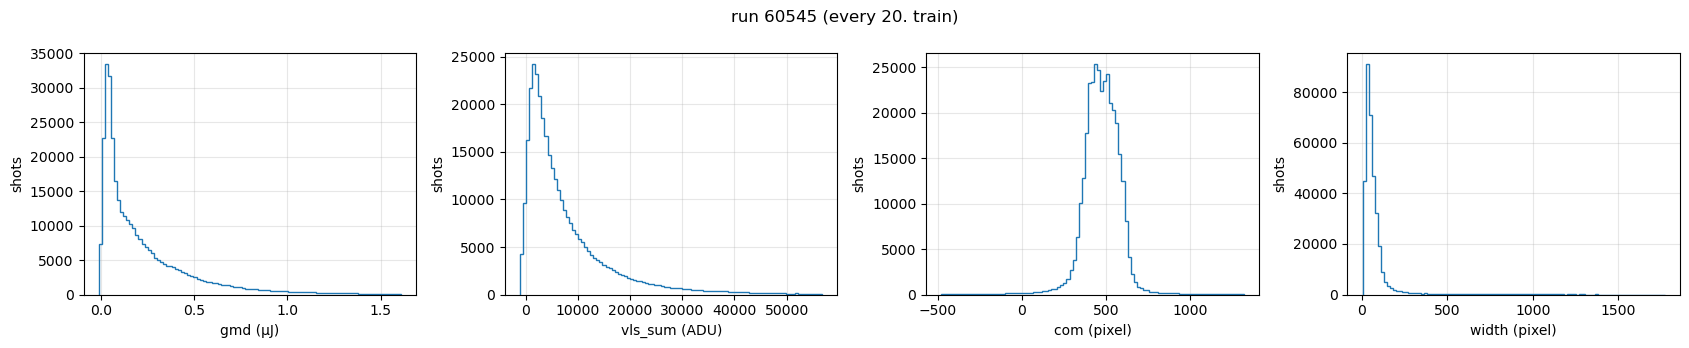

In [6]:
# Distributions of the per-shot values; shaded = filter range
fig, axs = plt.subplots(1, 4, figsize=(17, 3.5))
for ax, name, unit in zip(axs, ["gmd", "vls_sum", "com", "width"], ["µJ", "ADU", "pixel", "pixel"]):
    v = shots[name][np.isfinite(shots[name])]
    if len(v):
        lo, hi = np.percentile(v, [0.5, 99.5])
        edges = np.linspace(lo, hi, 100) if hi > lo else 20
        ax.hist(v, bins=edges, histtype="step")
    if FILTERS.get(name) is not None:
        ax.axvspan(*FILTERS[name], color="C1", alpha=0.15)
    ax.set(xlabel=f"{name} ({unit})", ylabel="shots")
fig.suptitle(source)
fig.tight_layout()
plt.show()

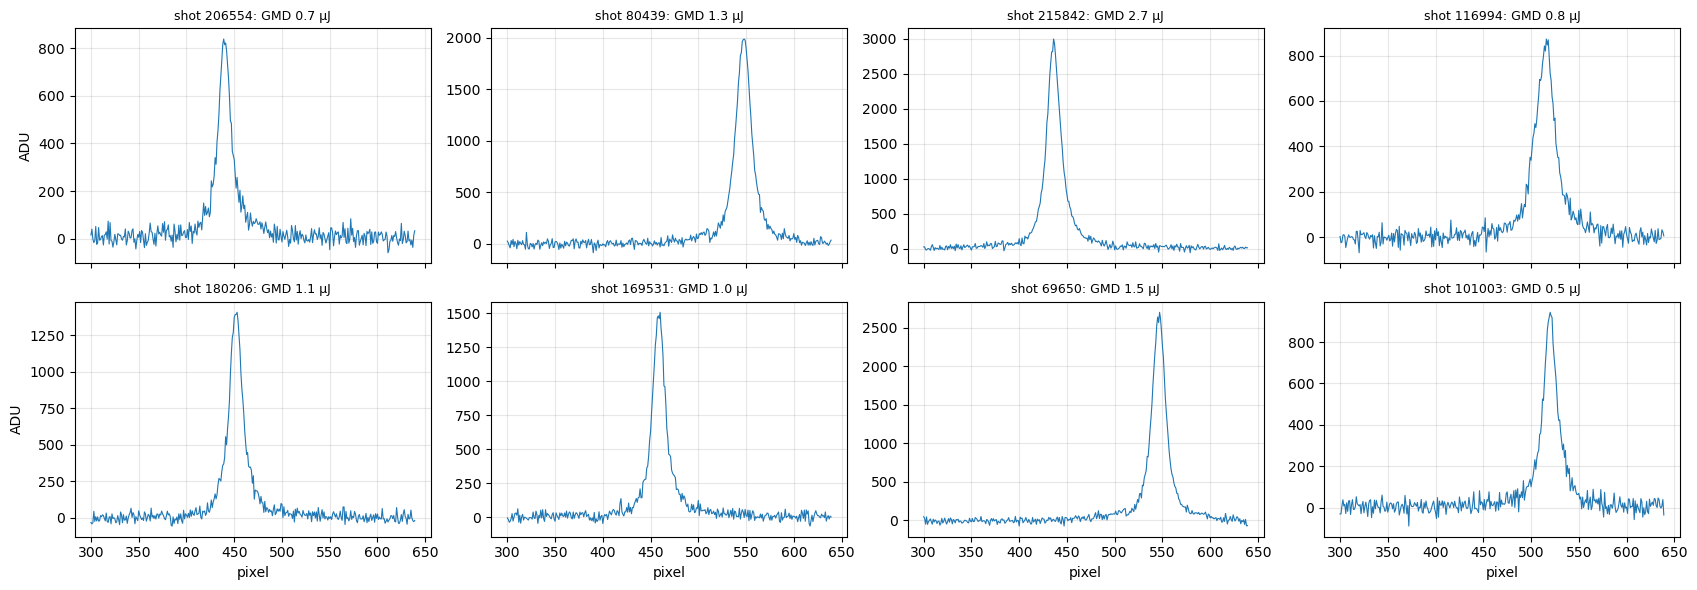

In [7]:
# A few strong single shots (optional COM and width overlays)
strongest = np.argsort(shots["vls_sum"])[::-1]
examples = np.random.default_rng(0).choice(strongest[:max(n_shots // 10, 8)], min(n_shots, 8), replace=False)
fig, axs = plt.subplots(2, 4, figsize=(17, 6), sharex=True)
for ax, i in zip(axs.flat, examples):
    ax.plot(px_roi, S[i], lw=0.8)
    # ax.axvline(com[i], color="C3", ls="--")
    # ax.axvspan(com[i] - width[i], com[i] + width[i], color="C3", alpha=0.12)
    ax.set_title(f"shot {i}: GMD {shots['gmd'][i]:.1f} µJ", fontsize=9)
for ax in axs.flat[len(examples):]:
    ax.set_visible(False)
for ax in axs[1]:
    ax.set_xlabel("pixel")
for ax in axs[:, 0]:
    ax.set_ylabel("ADU")
fig.tight_layout()
plt.show()

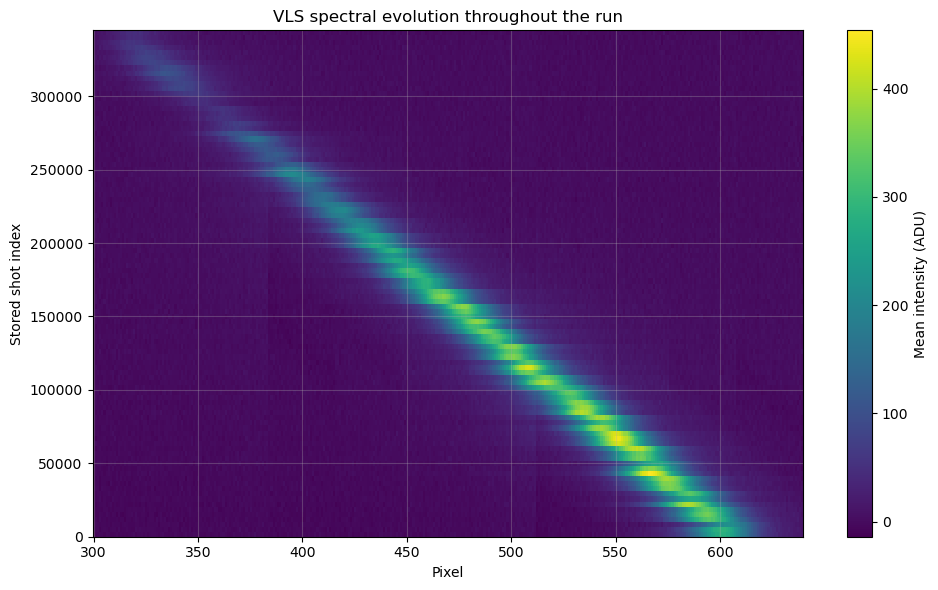

In [8]:
# Spectral evolution throughout the run
N_BLOCKS = min(100, n_shots)

edges = np.linspace(0, len(S), N_BLOCKS + 1, dtype=int)

means = []

for lo, hi in zip(edges[:-1], edges[1:]):
    spectra_block = S[lo:hi]
    means.append(np.nanmean(spectra_block, axis=0))

means = np.asarray(means)

fig, ax = plt.subplots(figsize=(10, 6))

im = ax.imshow(
    means,
    origin="lower",
    aspect="auto",
    interpolation="nearest",
    extent=(px_roi[0] - 0.5, px_roi[-1] + 0.5,
            0, len(S)),
    cmap="viridis"
)

fig.colorbar(im, ax=ax, label="Mean intensity (ADU)")

ax.set_xlabel("Pixel")
ax.set_ylabel("Stored shot index")
ax.set_title("VLS spectral evolution throughout the run")

ax.set_xlim(px_roi[0] - 0.5, px_roi[-1] + 0.5)

plt.tight_layout()
plt.show()

## 3. Incident photon energy vs Gotthard pixel

The OPIS channel contained only zeros in the saved run 60545 inspection. Use `set wavelength 1` (nm) to calculate the nominal photon energy, E = hc / λ. Each shot is assigned the most recent recorded setting by train ID; no extrapolation is made before or after the recorded settings. This is the nominal machine setting, not a measurement of the photon energy of each individual pulse. A step change may not be instantaneous; inspect the scan trace before interpreting the map.

Run 60545: 16 raw files
OPIS: 0.00000 - 0.00000; 1 unique values
XGM: 4.39660 - 4.67865; 97 unique values
Set wavelength 1: 4.39660 - 4.67865; 104 unique values
Set wavelength 2: 19.00000 - 19.00000; 1 unique values


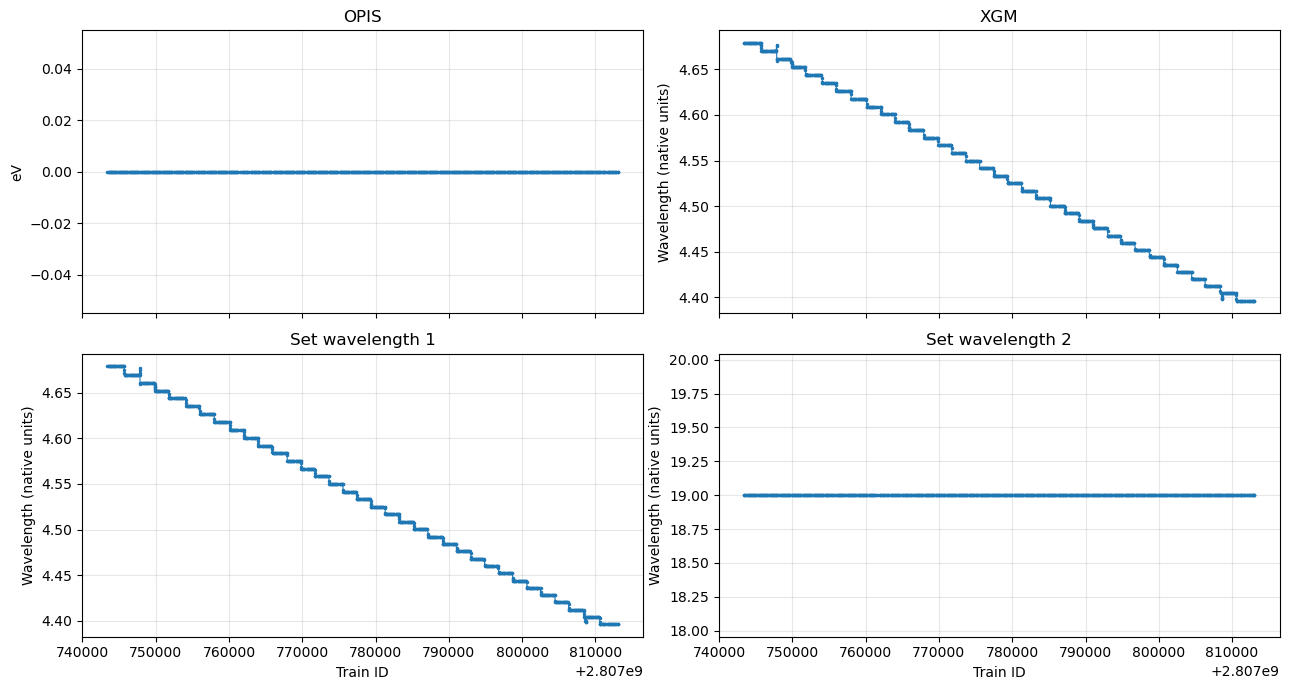

In [9]:
# Read only the wavelength and energy channels from the raw files of RUN
files = sorted(RAW_DIR.rglob(f"FLASH2_USER1_main_run{RUN}_*.h5"))
if not files:
    raise FileNotFoundError(f"No raw files for run {RUN} in {RAW_DIR}")
print(f"Run {RUN}: {len(files)} raw files")

# Inspect photon-energy and wavelength channels

channels = {
    "OPIS": "/FL2/Photon Diagnostic/Wavelength/OPIS tunnel/Processed/mean photon energy",
    "XGM": "/zraw/FLASH.FEL/XGM.PHOTONFLUX/FL2.TUNNEL/WAVELENGTH.USED/dGroup",
    "Set wavelength 1": "/Electron Diagnostic/Undulator setting/set wavelength 1",
    "Set wavelength 2": "/Electron Diagnostic/Undulator setting/set wavelength 2"
}

energy_data = {}

for label, channel in channels.items():

    tids, values = [], []

    for file in files:
        with h5py.File(file, "r") as f:
            if channel in f and "index" in f[channel] and "value" in f[channel]:
                tids.append(f[channel]["index"][:])
                values.append(f[channel]["value"][:])

    if not tids:
        continue

    tids = np.concatenate(tids)
    values = np.concatenate(values)

    tids = np.asarray(tids, dtype=np.int64).ravel()
    values = np.asarray(values).ravel()
    assert len(tids) == len(values), f"Unexpected channel shape: {label}"
    order = np.argsort(tids, kind="stable")
    energy_data[label] = {
        "train_id": tids[order],
        "value": values[order]
    }

fig, axs = plt.subplots(2, 2, figsize=(13, 7), sharex=True)

for ax, label in zip(axs.flat, channels):
    ax.set_title(label)
    ax.set_ylabel("eV" if label == "OPIS" else "Wavelength (native units)")
    if label not in energy_data:
        print(f"{label}: not available")
        continue
    values = energy_data[label]["value"]
    tids = energy_data[label]["train_id"]
    ax.plot(tids, values, ".-", lw=0.8, ms=3)
    ax.ticklabel_format(style="plain", axis="y", useOffset=False)
    finite_values = values[np.isfinite(values)]
    if len(finite_values):
        print(f"{label}: {finite_values.min():.5f} - {finite_values.max():.5f}; "
              f"{len(np.unique(finite_values))} unique values")

for ax in axs[1]:
    ax.set_xlabel("Train ID")
plt.tight_layout()
plt.show()

Assigned shots: 344916 / 344916


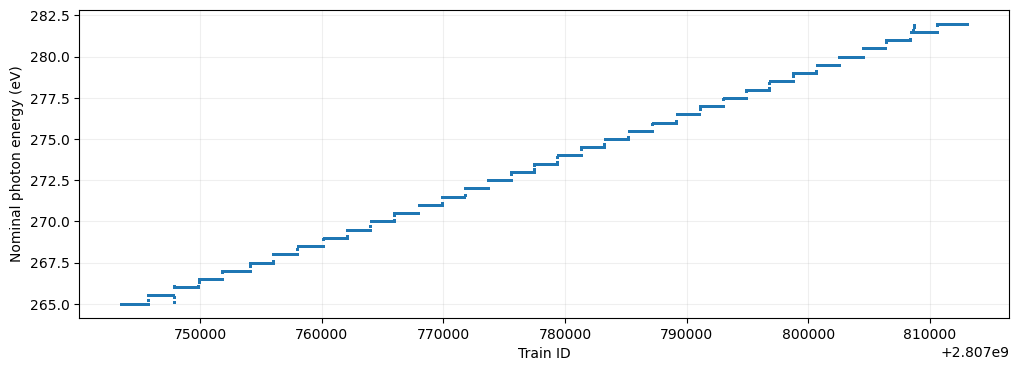

In [10]:
# Assign nominal FEL energy to Gotthard shots

HC = 1239.841984  # eV nm

train_ids = np.asarray(shots["train_id"])

if "Set wavelength 1" not in energy_data:
    raise ValueError("No set wavelength 1 channel; cannot assign nominal photon energy")
scan_ids = energy_data["Set wavelength 1"]["train_id"]
scan_wavelength = energy_data["Set wavelength 1"]["value"]

assert len(train_ids) == len(S)
assert len(scan_ids) and np.all(scan_ids[1:] >= scan_ids[:-1])
# Repeated train IDs are fine only if the recorded setting is the same
repeated = scan_ids[1:] == scan_ids[:-1]
if np.any(repeated & ~np.isclose(scan_wavelength[1:], scan_wavelength[:-1], equal_nan=True)):
    raise ValueError("Conflicting wavelength settings for the same train ID")

# Find the last recorded setting before each shot
idx = np.searchsorted(scan_ids, train_ids, side="right") - 1

# Do not extrapolate outside the recorded scan
valid = (idx >= 0) & (train_ids <= scan_ids[-1])

scan_energy = np.full(len(S), np.nan)

valid[valid] &= np.isfinite(scan_wavelength[idx[valid]]) & (scan_wavelength[idx[valid]] > 0)
scan_energy[valid] = HC / scan_wavelength[idx[valid]]

scan_energy[~np.isfinite(scan_energy) | (scan_energy <= 0)] = np.nan

print(f"Assigned shots: {np.isfinite(scan_energy).sum()} / {len(S)}")

plt.figure(figsize=(12, 4))
plt.plot(train_ids, scan_energy, ".", ms=2)
plt.xlabel("Train ID")
plt.ylabel("Nominal photon energy (eV)")
plt.grid(alpha=0.2)
plt.show()

Shots in scan steps: 343926 / 344916


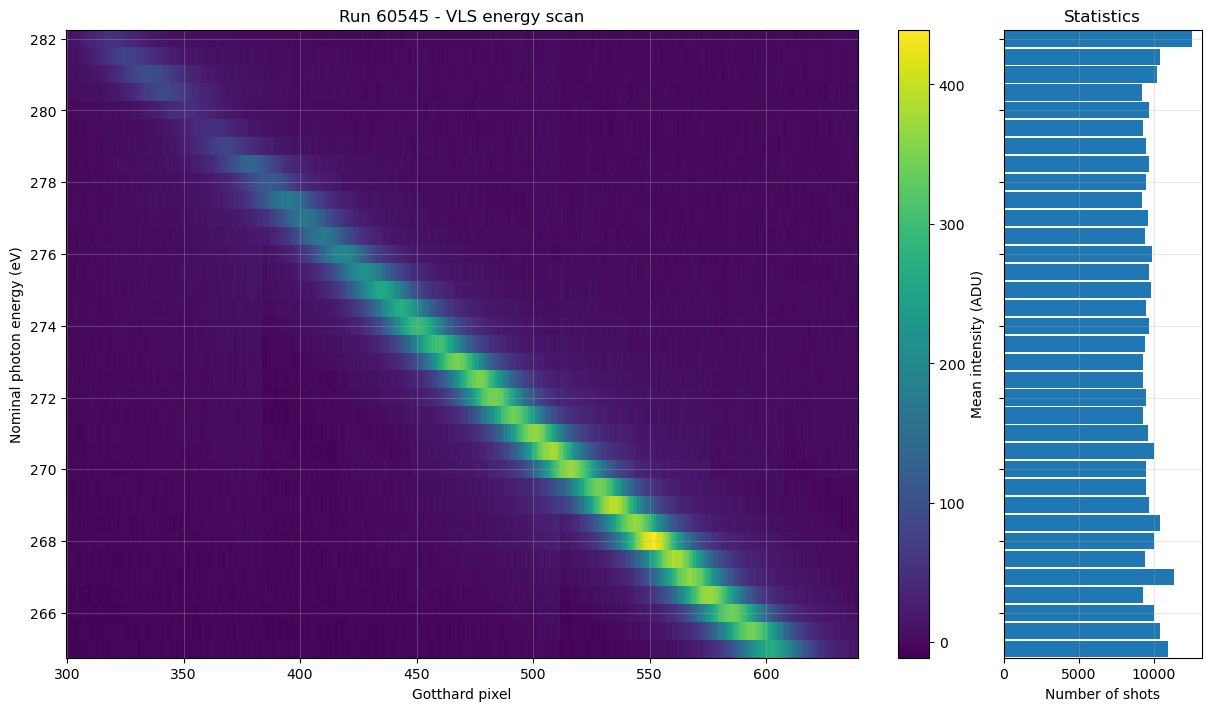

In [11]:
# Mean VLS spectra at each nominal photon-energy step
# No intensity or GMD cut: all processed shots within ENERGY_TOL contribute
assert ENERGY_STEP > 0 and 0 < ENERGY_TOL < ENERGY_STEP / 2
energies = np.arange(ENERGY_MIN, ENERGY_MAX + ENERGY_STEP / 2, ENERGY_STEP)
assert len(energies) and np.isclose(energies[-1], ENERGY_MAX)

means = np.full((len(energies), len(px_roi)), np.nan)
counts = np.zeros(len(energies), dtype=int)

finite = np.isfinite(S).all(axis=1)

for j, E in enumerate(energies):

    m = finite & (np.abs(scan_energy - E) <= ENERGY_TOL)

    counts[j] = m.sum()

    if counts[j] > 0:
        means[j] = S[m].mean(axis=0)

print(f"Shots in scan steps: {counts.sum()} / {len(S)}")
if not counts.any():
    raise ValueError("No shots in the requested energy steps; check the scan range")

fig, ax = plt.subplots(
    1, 2, figsize=(12, 7), sharey=True,
    gridspec_kw={"width_ratios": [4, 1]},
    constrained_layout=True
)

im = ax[0].imshow(
    means,
    origin="lower",
    aspect="auto",
    interpolation="nearest",
    extent=(px_roi[0] - 0.5, px_roi[-1] + 0.5,
            energies[0] - ENERGY_STEP / 2,
            energies[-1] + ENERGY_STEP / 2),
    cmap="viridis"
)

fig.colorbar(im, ax=ax[0], label="Mean intensity (ADU)")

ax[0].set_xlabel("Gotthard pixel")
ax[0].set_ylabel("Nominal photon energy (eV)")
ax[0].set_title(f"Run {RUN} - VLS energy scan")

ax[1].barh(energies, counts, height=ENERGY_STEP * 0.9)
ax[1].set_xlabel("Number of shots")
ax[1].set_title("Statistics")

plt.show()

## 4. Single shots and bunch structure

Inspect individual shots, the bunch pattern within a train and compare runs. Display normalisation affects only the individual-shot and comparison plots.
The train profile below compares integrated intensities before and after the additional train-wise background subtraction, on the raw-line axis. The active-bunch count is a diagnostic, not a cut.

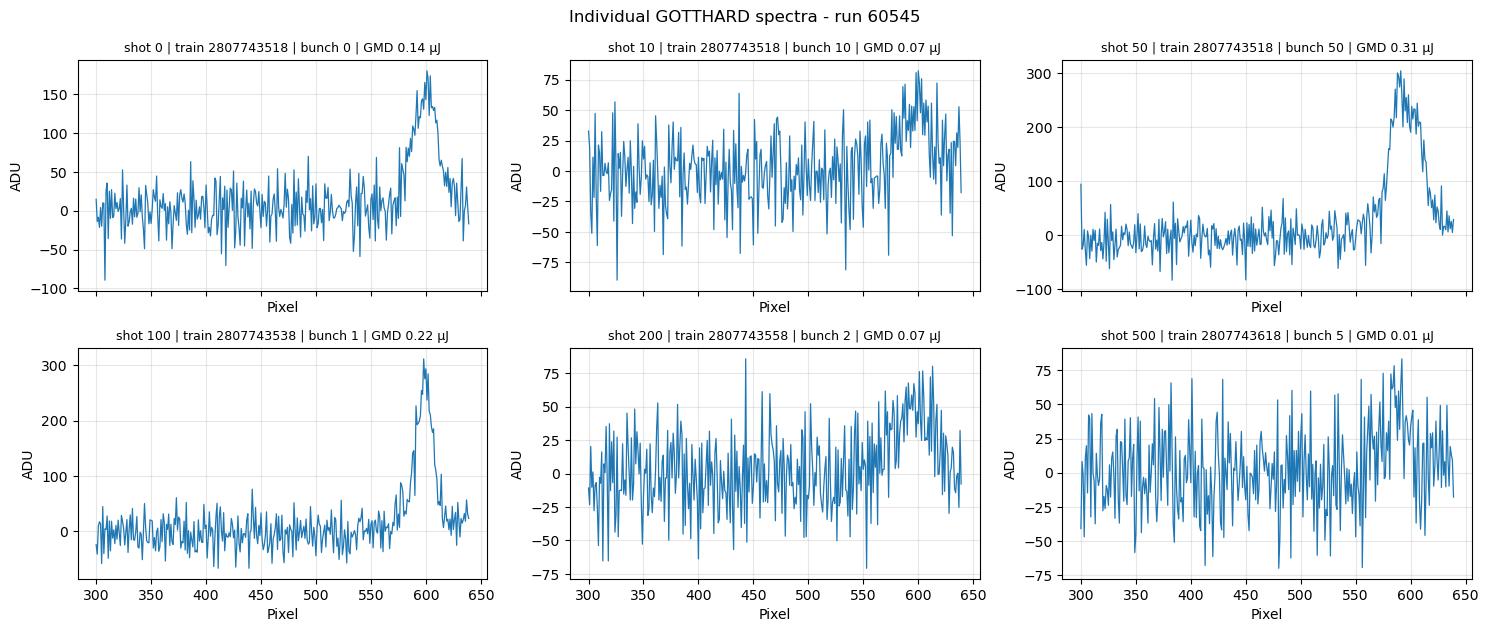

In [12]:
SHOW_RUN = RUN
SHOT_INDICES = [0, 10, 50, 100, 200, 500]

# Display normalisation used by the new diagnostic plots
def view_spectra(spectra):
    if VIEW_NORMALISE == "peak":
        scale = np.max(spectra, axis=1, keepdims=True)
    elif VIEW_NORMALISE == "area":
        scale = np.clip(spectra, 0, None).sum(axis=1, keepdims=True)
    else:
        return spectra
    return spectra / np.where(scale > 0, scale, np.nan)


run = runs[SHOW_RUN]
indices = np.asarray(SHOT_INDICES, dtype=int)
indices = indices[(indices >= 0) & (indices < len(run["S"]))]
if not len(indices):
    raise ValueError("No valid shot indices")
spectra = view_spectra(run["S"][indices])

ncols = 3
nrows = int(np.ceil(len(indices) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.2 * nrows), sharex=True)
axes = np.asarray(axes).ravel()

for ax, i, spec in zip(axes, indices, spectra):
    ax.plot(px_roi, spec, lw=0.9)
    ax.set_title(
        f"shot {i} | train {run['shots']['train_id'][i]} | "
        f"bunch {run['shots']['slot'][i]} | GMD {run['shots']['gmd'][i]:.2f} µJ",
        fontsize=9,
    )
    ax.set_xlabel("Pixel")
    ax.set_ylabel("ADU" if VIEW_NORMALISE is None else "Normalised intensity")
    ax.grid(alpha=0.3)

for ax in axes[len(indices):]:
    ax.set_visible(False)

fig.suptitle(f"Individual GOTTHARD spectra - run {SHOW_RUN}")
fig.tight_layout()
plt.show()

Run 60545, train 2807743518
GMD range: None
Single train: 99 pulses
Average: 25 trains, 2475 pulses
Shots per populated bunch in average: 25 to 25


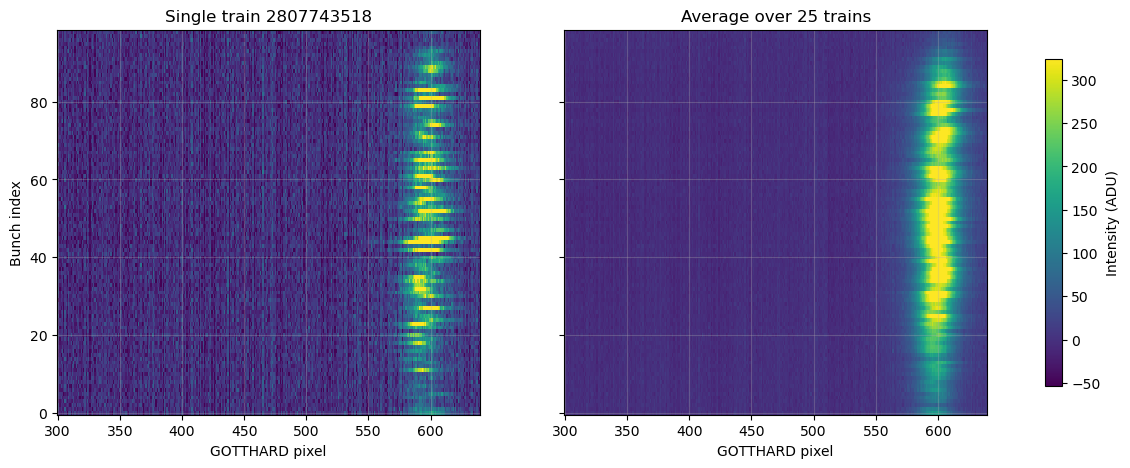

In [13]:
# ---- GOTTHARD single train and train-averaged image --------------------------
TRAIN_RUN = RUN
TRAIN_INDEX = 0               # Which loaded train to show
AVG_START = 0                 # First loaded train used for averaging
AVG_N_TRAINS = 25             # Number of loaded trains to average
TRAIN_GMD_RANGE = None        # e.g. (10.0, 12.0) µJ; None = all pulses

run = runs[TRAIN_RUN]
S_run = run["S"]
gmd = run["shots"]["gmd"]
slots = run["shots"]["slot"]
train_ids = run["shots"]["train_id"]

unique_trains = np.unique(train_ids)
train_id = unique_trains[TRAIN_INDEX]
avg_trains = unique_trains[AVG_START:AVG_START + AVG_N_TRAINS]

# Select pulses
train_keep = np.isfinite(gmd)
if TRAIN_GMD_RANGE is not None:
    lo, hi = TRAIN_GMD_RANGE
    train_keep &= (gmd >= lo) & (gmd < hi)

single_sel = train_keep & (train_ids == train_id)
avg_sel = train_keep & np.isin(train_ids, avg_trains)

n_slots = int(slots.max()) + 1
single = np.full((n_slots, len(px_roi)), np.nan)
average = np.full_like(single, np.nan)
n_per_slot = np.zeros(n_slots, dtype=int)

# Individual pulses from one train
single[slots[single_sel]] = S_run[single_sel]

# Mean spectrum at each bunch position, averaged over selected trains
for b in range(n_slots):
    sel = avg_sel & (slots == b)
    n_per_slot[b] = sel.sum()
    if sel.any():
        average[b] = S_run[sel].mean(axis=0)

print(f"Run {TRAIN_RUN}, train {int(train_id)}")
print(f"GMD range: {TRAIN_GMD_RANGE}")
print(f"Single train: {single_sel.sum()} pulses")
print(f"Average: {len(avg_trains)} trains, {avg_sel.sum()} pulses")
if n_per_slot.any():
    print(f"Shots per populated bunch in average: {n_per_slot[n_per_slot > 0].min()} to {n_per_slot.max()}")

# Shared colour limits
values = np.concatenate([single[np.isfinite(single)], average[np.isfinite(average)]])
if not len(values):
    raise ValueError("No shots in selected trains and GMD range")
vmin, vmax = np.percentile(values, [1, 99])

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharex=True, sharey=True)

for ax, image in zip(axes, [single, average]):
    im = ax.imshow(
        image, origin="lower", aspect="auto", interpolation="nearest",
        extent=(px_roi[0] - 0.5, px_roi[-1] + 0.5, -0.5, n_slots - 0.5),
        cmap="viridis", vmin=vmin, vmax=vmax,
    )
    ax.set_xlabel("GOTTHARD pixel")

axes[0].set_title(f"Single train {int(train_id)}")
axes[1].set_title(f"Average over {len(avg_trains)} trains")
axes[0].set_ylabel("Bunch index")

fig.colorbar(im, ax=axes, label="Intensity (ADU)", shrink=0.85)
plt.show()

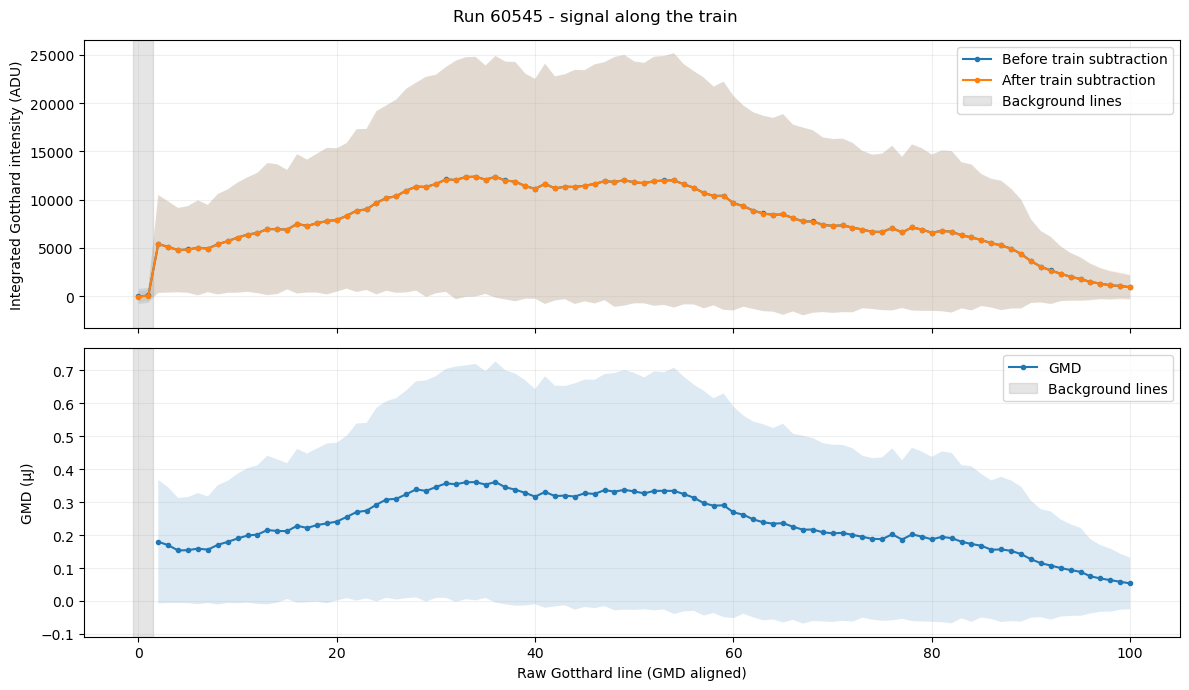

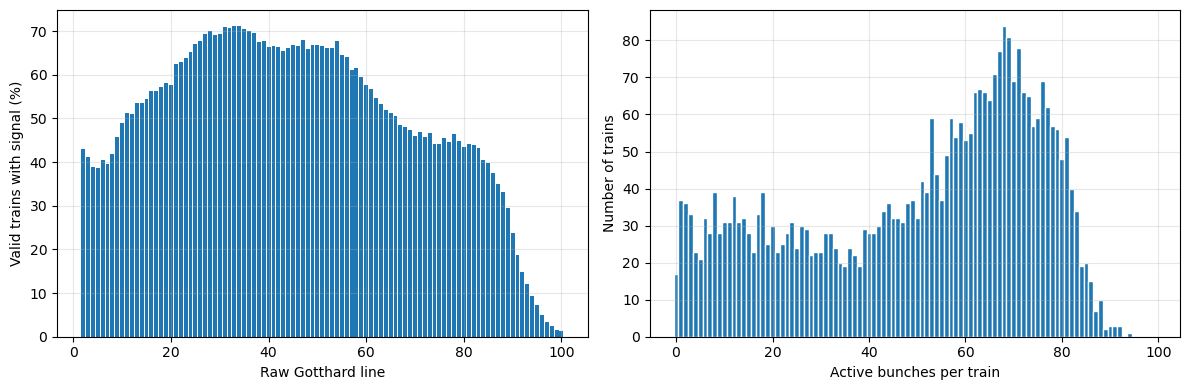

Background noise: 771.2 ADU; signal threshold: 4722.6 ADU
Mean / median / max active bunches: 50.0 / 57.0 / 94


In [14]:
# ---- Signal along the train and active bunches ------------------------------
DIAG_RUN = RUN
N_SIGMA = 5

diag = runs[DIAG_RUN]["train_diag"]
vls_train = diag["before"]
vls_corrected = diag["after"]
gmd_train = diag["gmd"]
lines = np.arange(vls_train.shape[1])

fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for a, values, label in ((ax[0], vls_train, "Before train subtraction"),
                         (ax[0], vls_corrected, "After train subtraction"),
                         (ax[1], gmd_train, "GMD")):
    m = np.isfinite(values).any(axis=0)
    mean = np.nanmean(values[:, m], axis=0)
    sd = np.nanstd(values[:, m], axis=0)
    a.plot(lines[m], mean, "o-", ms=3, label=label)
    a.fill_between(lines[m], mean-sd, mean+sd, alpha=0.15)

for a in ax:
    if N_BG:
        a.axvspan(-0.5, N_BG-0.5, color="grey", alpha=0.2, label="Background lines")
    a.legend()
    a.grid(alpha=0.2)
ax[0].set_ylabel("Integrated Gotthard intensity (ADU)")
ax[1].set_ylabel("GMD (µJ)")
ax[1].set_xlabel("Raw Gotthard line (GMD aligned)")
fig.suptitle(f"Run {DIAG_RUN} - signal along the train")
plt.tight_layout()
plt.show()

if N_BG == 2:
    # Noise from the difference of the two background frames
    noise = np.nanstd(vls_train[:, 0] - vls_train[:, 1]) / np.sqrt(2)
    threshold = N_SIGMA * noise * np.sqrt(1 + 1/N_BG)
    signal = vls_corrected[:, N_BG:]
    valid = np.isfinite(signal)
    active = valid & (signal > threshold)
    n_active = active.sum(axis=1)
    n_valid = valid.sum(axis=0)
    m = n_valid > 0
    fraction_active = active[:, m].sum(axis=0) / n_valid[m]

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].bar(lines[N_BG:][m], 100*fraction_active)
    ax[0].set(xlabel="Raw Gotthard line", ylabel="Valid trains with signal (%)")
    ax[1].hist(n_active, bins=np.arange(-0.5, signal.shape[1]+1.5), edgecolor="white")
    ax[1].set(xlabel="Active bunches per train", ylabel="Number of trains")
    plt.tight_layout()
    plt.show()
    print(f"Background noise: {noise:.1f} ADU; signal threshold: {threshold:.1f} ADU")
    print(f"Mean / median / max active bunches: {n_active.mean():.1f} / {np.median(n_active):.1f} / {n_active.max()}")
else:
    print("Active-bunch noise estimate requires two background lines")

run 60545: 100 shots selected


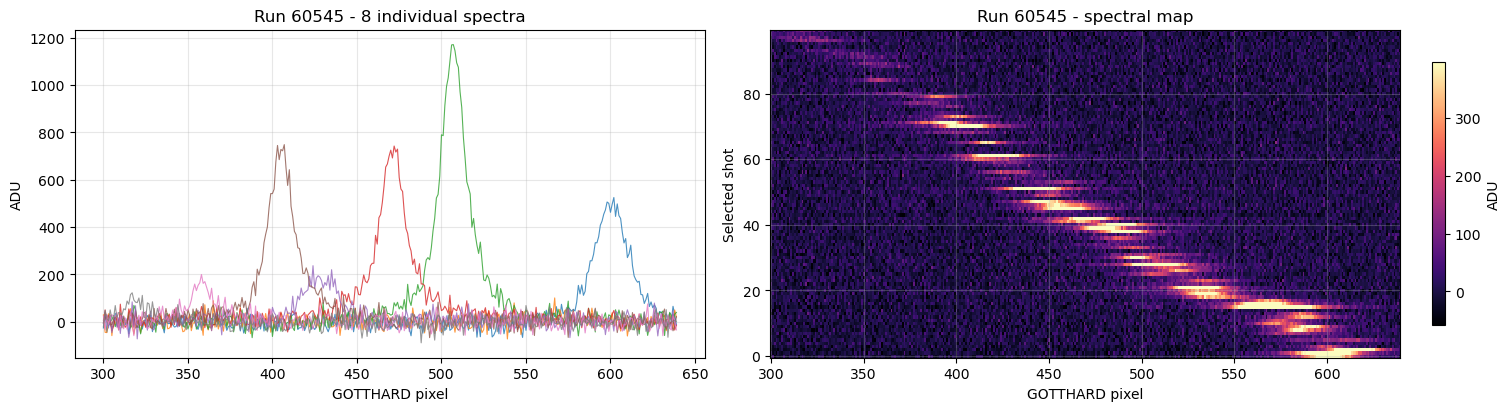

In [15]:
COMPARE_N_SHOTS = 100
COMPARE_OVERLAY = 8
COMPARE_GMD_RANGE = None

# Select a reproducible set of shots from each run
rng = np.random.default_rng(0)
comparison = {}

for run_no in RUNS:
    run = runs[run_no]
    gmd = run["shots"]["gmd"]

    valid = np.isfinite(gmd)
    if COMPARE_GMD_RANGE is not None:
        lo, hi = COMPARE_GMD_RANGE
        valid &= (gmd >= lo) & (gmd <= hi)

    indices = np.flatnonzero(valid)
    if len(indices) > COMPARE_N_SHOTS:
        indices = np.sort(rng.choice(indices, COMPARE_N_SHOTS, replace=False))

    if len(indices) == 0:
        print(f"run {run_no}: no shots in selected GMD range")
        continue

    comparison[run_no] = view_spectra(run["S"][indices])
    print(f"run {run_no}: {len(indices)} shots selected")

# Shared intensity scale for the maps
if not comparison:
    raise ValueError("No shots selected for comparison")
values = np.concatenate([s.ravel() for s in comparison.values()])
vmin, vmax = np.nanpercentile(values, [1, 99])

fig, axes = plt.subplots(len(comparison), 2, figsize=(15, 4 * len(comparison)),
                         squeeze=False, constrained_layout=True)

for row, (run_no, spectra) in enumerate(comparison.items()):
    ax_spec, ax_map = axes[row]

    # A few individual spectra
    selected = np.linspace(0, len(spectra) - 1,
                           min(COMPARE_OVERLAY, len(spectra)), dtype=int)

    for i in selected:
        ax_spec.plot(px_roi, spectra[i], lw=0.8, alpha=0.8)

    ax_spec.set_xlabel("GOTTHARD pixel")
    ax_spec.set_ylabel("ADU" if VIEW_NORMALISE is None else "Normalised intensity")
    ax_spec.set_title(f"Run {run_no} - {len(selected)} individual spectra")
    ax_spec.grid(alpha=0.3)

    # Shot-by-shot map
    im = ax_map.imshow(
        spectra, origin="lower", aspect="auto", interpolation="nearest",
        extent=(px_roi[0] - 0.5, px_roi[-1] + 0.5, -0.5, len(spectra) - 0.5),
        vmin=vmin, vmax=vmax, cmap="magma",
    )
    ax_map.set_xlabel("GOTTHARD pixel")
    ax_map.set_ylabel("Selected shot")
    ax_map.set_title(f"Run {run_no} - spectral map")

fig.colorbar(im, ax=axes[:, 1].tolist(), label="ADU" if VIEW_NORMALISE is None else "Normalised intensity", shrink=0.8)
plt.show()

## 5. Average spectra and moment checks

These plots use `FILTERS` only. Bin edges are percentiles of the selected shot values (unless explicit edges are supplied). The COM check compares the spectral position with the COM bin. The width check first aligns shots by their COM in integer pixels, then compares the width of the averaged spectrum with the width bin. The agreement is a diagnostic, not an independent calibration.

In [16]:
# Binning helpers
def edges_for(x, n_bins=None, percentiles=None):
    # BIN_EDGES if given, else equally spaced percentile levels of x
    if BIN_EDGES is not None and n_bins is None:
        return np.asarray(BIN_EDGES, dtype=float)
    if not len(x):
        raise ValueError("No finite shots for binning; check FILTERS")
    lo, hi = percentiles or BIN_PERCENTILES
    return np.unique(np.nanpercentile(x, np.linspace(lo, hi, (n_bins or N_BINS) + 1)))


def colours(n, cmap="viridis"):
    return mpl.colormaps[cmap](np.linspace(0, 0.95, n))


def bin_spectra(x, edges, spectra, g, normalise=None):
    if len(edges) < 2 or np.any(np.diff(edges) <= 0):
        raise ValueError("Binning needs at least two increasing edges")
    cents = (edges[:-1] + edges[1:]) / 2
    avg = np.full((len(cents), spectra.shape[1]), np.nan)
    n = np.zeros(len(cents), dtype=int)
    for j, (lo, hi) in enumerate(zip(edges[:-1], edges[1:])):
        m = (x >= lo) & ((x <= hi) if j == len(cents) - 1 else (x < hi))
        n[j] = m.sum()
        if not n[j]:
            continue
        if normalise == "gmd":
            denom = g[m].sum()
            if denom > 0:
                avg[j] = spectra[m].sum(axis=0) / denom
        else:
            avg[j] = spectra[m].mean(axis=0)
            if normalise == "area":
                area = avg[j].sum()
                avg[j] = avg[j] / area if area != 0 else np.nan
    return cents, avg, n


keep = np.ones(n_shots, bool)
for name, rng in FILTERS.items():
    if rng is not None:
        lo, hi = rng
        keep &= (shots[name] >= lo) & (shots[name] <= hi)
        print(f"{name} in [{lo}, {hi}]: {keep.sum()} shots left")
print(f"kept {keep.sum()} of {n_shots} shots")

kept 344916 of 344916 shots


shots per bin: [41390, 41389, 41390, 41390, 41390, 41390, 41389, 41390]


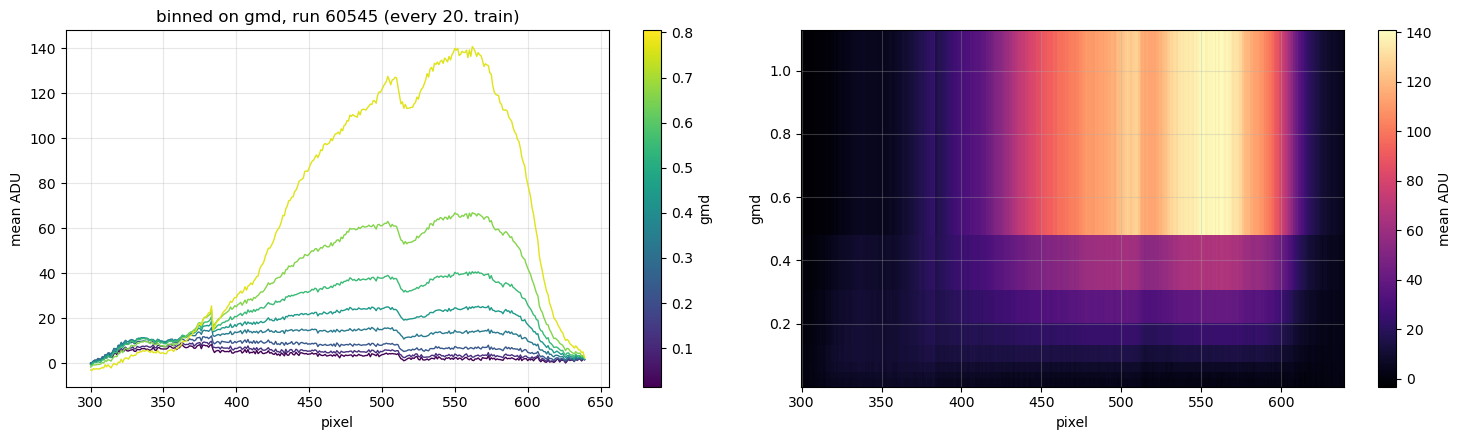

In [17]:
bin_keep = keep & np.isfinite(shots[BIN_ON])
x = shots[BIN_ON][bin_keep]
edges = edges_for(x)
cents, avg, n_in = bin_spectra(x, edges, S[bin_keep], shots["gmd"][bin_keep], normalise=NORMALISE)
print("shots per bin:", n_in.tolist())

ylabel = {None: "mean ADU", "gmd": "ADU / µJ", "area": "normalised"}[NORMALISE]
fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
for c, spec_bin, col in zip(cents, avg, colours(len(cents))):
    axs[0].plot(px_roi, spec_bin, color=col, lw=1)
sm = mpl.cm.ScalarMappable(mpl.colors.Normalize(cents.min(), cents.max()), "viridis")
fig.colorbar(sm, ax=axs[0], label=BIN_ON)
axs[0].set(xlabel="pixel", ylabel=ylabel, title=f"binned on {BIN_ON}, {source}")
px_edges = np.append(px_roi, px_roi[-1] + 1) - 0.5           # pixel bin edges for pcolormesh
mesh = axs[1].pcolormesh(px_edges, edges, avg, shading="flat", cmap="magma")
fig.colorbar(mesh, ax=axs[1], label=ylabel)
axs[1].set(xlabel="pixel", ylabel=BIN_ON)
fig.tight_layout()
plt.show()

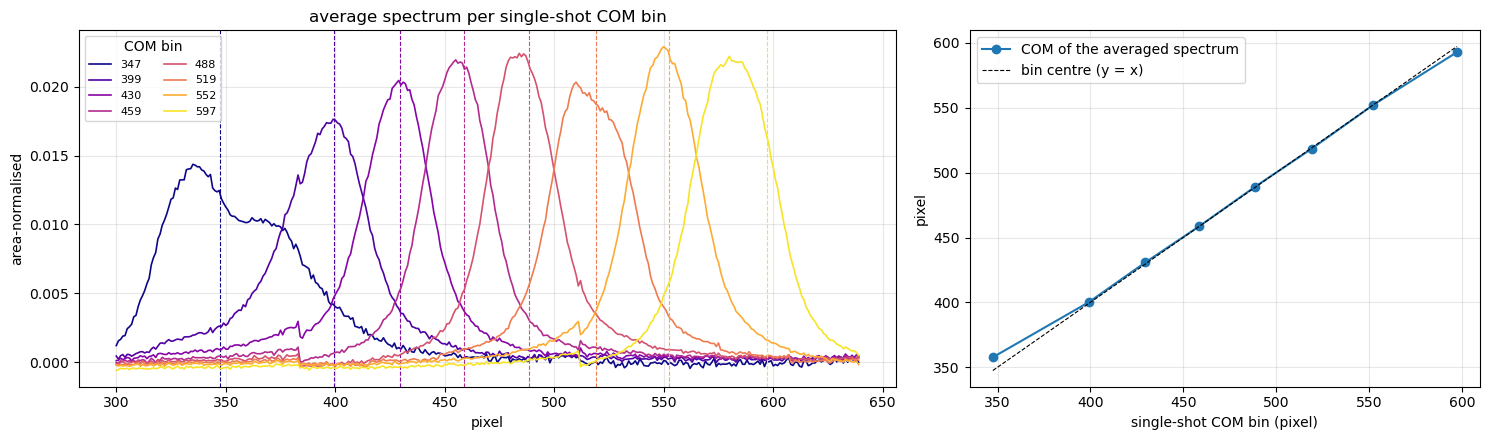

In [18]:
N_CHECK_BINS = 8
com_keep = keep & np.isfinite(com)
x = com[com_keep]
edges_c = edges_for(x, N_CHECK_BINS, (5, 95))
cents_c, avg_c, n_c = bin_spectra(x, edges_c, S[com_keep], shots["gmd"][com_keep], normalise="area")
_, com_of_avg, _ = processing.spectral_moments(avg_c, px_roi)

fig, axs = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1.6, 1]})
for c, spec_bin, col in zip(cents_c, avg_c, colours(len(cents_c), "plasma")):
    axs[0].plot(px_roi, spec_bin, color=col, lw=1.2, label=f"{c:.0f}")
    axs[0].axvline(c, color=col, ls="--", lw=0.8)
axs[0].set(xlabel="pixel", ylabel="area-normalised", title="average spectrum per single-shot COM bin")
axs[0].legend(title="COM bin", fontsize=8, ncol=2)
axs[1].plot(cents_c, com_of_avg, "o-", label="COM of the averaged spectrum")
axs[1].plot(cents_c, cents_c, "k--", lw=0.8, label="bin centre (y = x)")
axs[1].set(xlabel="single-shot COM bin (pixel)", ylabel="pixel")
axs[1].legend()
fig.tight_layout()
plt.show()

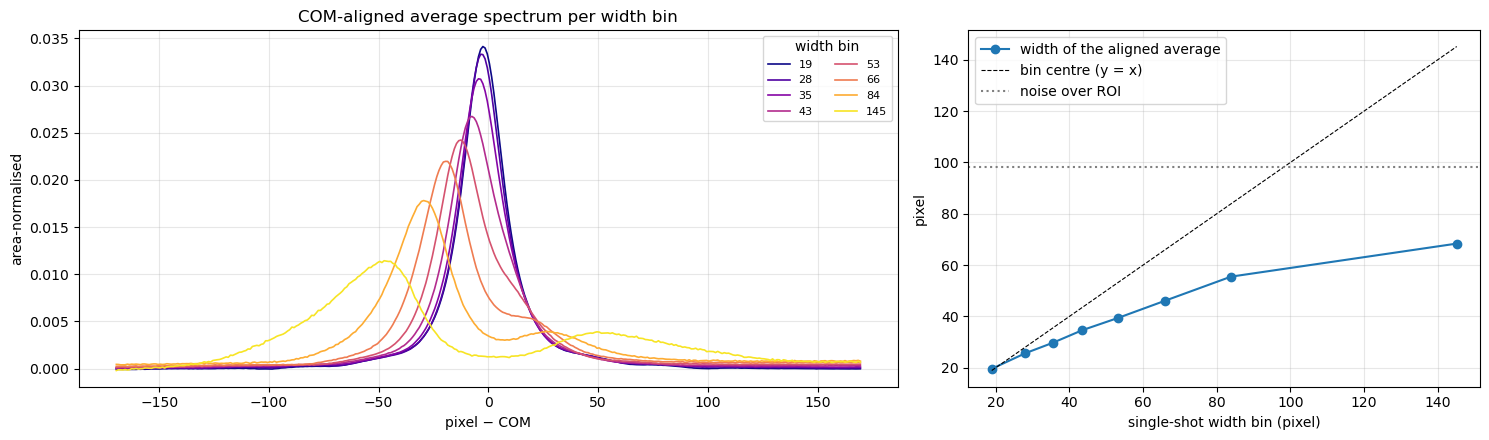

In [19]:
# Align the shots in blocks; keep the original clipped-edge convention
# Use the same percentile range as the COM check; finite COM and width are required
width_keep = keep & np.isfinite(com) & np.isfinite(width)
x = width[width_keep]
edges_w = edges_for(x, N_CHECK_BINS, (5, 95))
if len(edges_w) < 2:
    raise ValueError("Not enough distinct widths to bin")
cents_w = (edges_w[:-1] + edges_w[1:]) / 2
centre = px_roi.mean()
shift = np.round(com[width_keep] - centre).astype(int)
ids = np.flatnonzero(width_keep)

avg_w = np.full((len(cents_w), len(px_roi)), np.nan)
n_w = np.zeros(len(cents_w), dtype=int)
for j, (lo, hi) in enumerate(zip(edges_w[:-1], edges_w[1:])):
    ii = np.flatnonzero((x >= lo) & ((x <= hi) if j == len(cents_w) - 1 else (x < hi)))
    n_w[j] = len(ii)
    if not len(ii):
        continue
    total = np.zeros(len(px_roi))
    for start in range(0, len(ii), 10000):
        block = ii[start:start + 10000]
        idx = np.clip(np.arange(len(px_roi))[None, :] + shift[block, None], 0, len(px_roi) - 1)
        total += np.take_along_axis(S[ids[block]], idx, axis=1).sum(axis=0)
    if total.sum() != 0:
        avg_w[j] = total / total.sum()

_, _, width_of_avg = processing.spectral_moments(avg_w, px_roi)

fig, axs = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1.6, 1]})
for c, spec_bin, col in zip(cents_w, avg_w, colours(len(cents_w), "plasma")):
    axs[0].plot(px_roi - centre, spec_bin, color=col, lw=1.2, label=f"{c:.0f}")
axs[0].set(xlabel="pixel − COM", ylabel="area-normalised", title="COM-aligned average spectrum per width bin")
axs[0].legend(title="width bin", fontsize=8, ncol=2)
axs[1].plot(cents_w, width_of_avg, "o-", label="width of the aligned average")
axs[1].plot(cents_w, cents_w, "k--", lw=0.8, label="bin centre (y = x)")
axs[1].axhline(len(px_roi) / np.sqrt(12), color="gray", ls=":", label="noise over ROI")
axs[1].set(xlabel="single-shot width bin (pixel)", ylabel="pixel")
axs[1].legend()
fig.tight_layout()
plt.show()

## 6. GMD vs integrated Gotthard intensity

The default uses all positive-GMD shots. Set `CORR_ENERGY` to compare at a single nominal photon energy. The optional strongest-shot selection operates either within each energy step or within each GMD bin. Selection by Gotthard intensity biases the correlation, so use the all-shot, fixed-energy result for a linearity check. The pooled correlation can mix different spectral responses at different energies.
The second plot compares the same matched shots before and after the train-wise subtraction. If strongest-shot selection is enabled, it is based on corrected intensity in both panels.

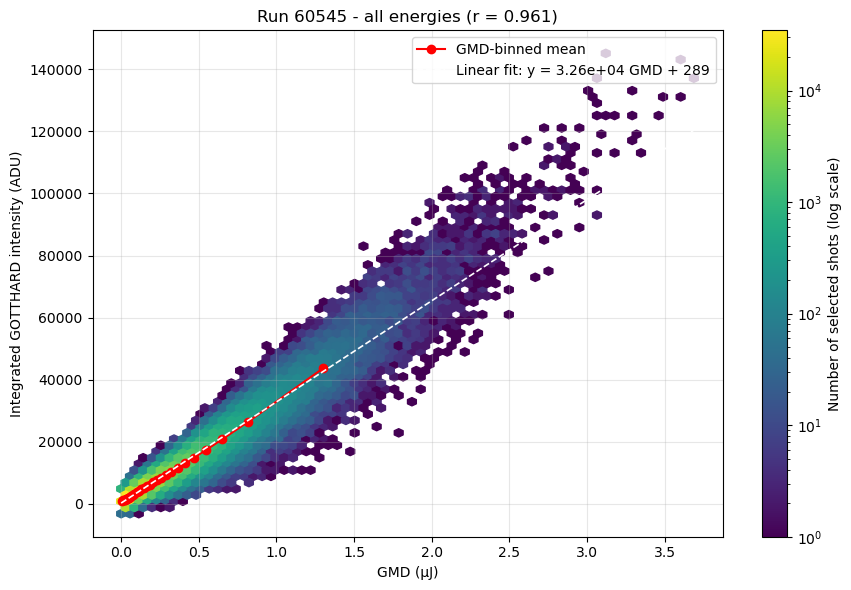

All shots:      338545 | Pearson r = 0.961
Selected shots: 338545 | Pearson r = 0.961
Fit equation:   y = 3.26e+04 GMD + 289


In [33]:
CORR_GMD_RANGE = None
CORR_N_BINS = 30
CORR_ENERGY = None           # e.g. 270.0 eV; None = all energies
CORR_N_STRONGEST = None      # None = all shots
CORR_SELECT_BY = "gmd"       # "gmd" or "energy" when selecting strongest shots
CORR_POLY_DEGREE = 1         # 1 = linear, 2 = quadratic, etc.

# Use the primary run, with its own scan_energy array
gmd = shots["gmd"]
vls_sum = shots["vls_sum"]
valid = np.isfinite(gmd) & np.isfinite(vls_sum) & (gmd > 0)
if CORR_GMD_RANGE is not None:
    lo, hi = CORR_GMD_RANGE
    valid &= (gmd >= lo) & (gmd < hi)
if CORR_ENERGY is not None:
    valid &= np.abs(scan_energy - CORR_ENERGY) <= ENERGY_TOL

g, v = gmd[valid], vls_sum[valid]
if len(g) < 2 or np.ptp(g) == 0 or np.ptp(v) == 0:
    raise ValueError("Insufficient variation in selected shots")

edges = np.unique(np.percentile(g, np.linspace(0, 100, CORR_N_BINS + 1)))
bins = np.digitize(g, edges[1:-1])
selected = np.ones(len(g), dtype=bool)
if CORR_N_STRONGEST is not None:
    selected[:] = False
    if CORR_SELECT_BY == "energy":
        groups = [np.flatnonzero(np.abs(scan_energy[valid] - E) <= ENERGY_TOL) for E in energies]
    elif CORR_SELECT_BY == "gmd":
        groups = [np.flatnonzero(bins == j) for j in range(len(edges) - 1)]
    else:
        raise ValueError("CORR_SELECT_BY must be 'gmd' or 'energy'")
    for ii in groups:
        selected[ii[np.argsort(v[ii])[::-1]][:CORR_N_STRONGEST]] = True


def gmd_bin_means(mask):
    mean_g, mean_v = [], []
    for j in range(len(edges) - 1):
        m = mask & (bins == j)
        if m.any():
            mean_g.append(g[m].mean())
            mean_v.append(v[m].mean())
    return np.asarray(mean_g), np.asarray(mean_v)


def format_poly_equation(coeffs, var="x"):
    terms = []
    deg = len(coeffs) - 1
    for idx, c in enumerate(coeffs):
        power = deg - idx
        if np.isclose(c, 0.0, atol=1e-12):
            continue
        sign = "-" if c < 0 else "+"
        mag = abs(c)
        if power == 0:
            val_str = f"{mag:.3g}"
        elif power == 1:
            val_str = f"{mag:.3g} {var}"
        else:
            val_str = f"{mag:.3g} {var}^{power}"

        if not terms:
            terms.append(f"-{val_str}" if c < 0 else val_str)
        else:
            terms.append(f" {sign} {val_str}")
    return "".join(terms) if terms else "0"


mean_g_all, mean_v_all = gmd_bin_means(np.ones(len(g), dtype=bool))
mean_g, mean_v = gmd_bin_means(selected)
g_sel, v_sel = g[selected], v[selected]
if len(g_sel) < 2 or np.ptp(g_sel) == 0 or np.ptp(v_sel) == 0:
    raise ValueError("Insufficient variation after strongest-shot selection")

deg = min(CORR_POLY_DEGREE, len(np.unique(g_sel)) - 1)
poly_coeffs = np.polyfit(g_sel, v_sel, deg)
poly_eq = format_poly_equation(poly_coeffs, var="GMD")
poly_label = "Linear fit" if deg == 1 else f"Poly (deg {deg})"
fit_legend = f"{poly_label}: y = {poly_eq}"

g_grid = np.linspace(g_sel.min(), g_sel.max(), 200)
v_fit = np.polyval(poly_coeffs, g_grid)

r_all = np.corrcoef(g, v)[0, 1]
r = np.corrcoef(g_sel, v_sel)[0, 1]

fig, ax = plt.subplots(figsize=(9, 6))
hb = ax.hexbin(g_sel, v_sel, gridsize=65, bins="log", mincnt=1, cmap="viridis")
fig.colorbar(hb, ax=ax, label="Number of selected shots (log scale)")
if CORR_N_STRONGEST is not None:
    ax.plot(mean_g_all, mean_v_all, "o-", color="grey", lw=1.5, label="All shots")
ax.plot(mean_g, mean_v, "o-", color="red", lw=1.5, label="GMD-binned mean")
ax.plot(g_grid, v_fit, "w--", lw=1.2, label=fit_legend)
ax.set_xlabel("GMD (µJ)")
ax.set_ylabel("Integrated GOTTHARD intensity (ADU)")
energy_label = "all energies" if CORR_ENERGY is None else f"{CORR_ENERGY:.1f} eV"
ax.set_title(f"Run {RUN} - {energy_label} (r = {r:.3f})")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

print(f"All shots:      {len(g)} | Pearson r = {r_all:.3f}")
print(f"Selected shots: {len(g_sel)} | Pearson r = {r:.3f}")
print(f"Fit equation:   y = {poly_eq}")

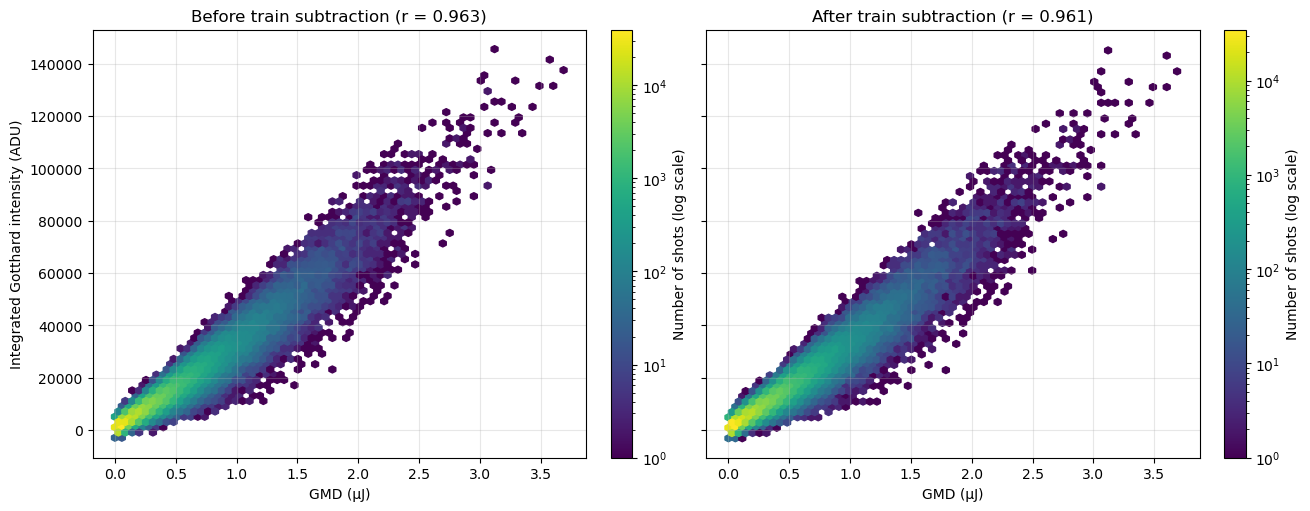

In [21]:
# Compare the correlation on exactly the same matched shots before and after
vls_before = shots["vls_sum_before"][valid][selected]
paired = np.isfinite(vls_before) & np.isfinite(v_sel) & np.isfinite(g_sel)
fig, ax = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True, constrained_layout=True)
for a, values, label in ((ax[0], vls_before, "Before train subtraction"),
                         (ax[1], v_sel, "After train subtraction")):
    r_pair = np.corrcoef(g_sel[paired], values[paired])[0, 1]
    hb = a.hexbin(g_sel[paired], values[paired], gridsize=65, bins="log", mincnt=1, cmap="viridis")
    fig.colorbar(hb, ax=a, label="Number of shots (log scale)")
    a.set(xlabel="GMD (µJ)", title=f"{label} (r = {r_pair:.3f})")
ax[0].set_ylabel("Integrated Gotthard intensity (ADU)")
plt.show()

## 7. Optional: Gaussian fits of the strongest spectra

Set `FIT_GAUSSIANS = True` to fit the strongest 200 shots per energy step (ranked by integrated Gotthard intensity). Fits must pass the R² cut and lie within the ROI. The plotted error bars give the 16th–84th percentile range of accepted fits, not the uncertainty of the median. FWHM is in pixels and includes instrumental broadening. A good fit is not proof of a single FEL spike. This section can be slow.

In [27]:
FIT_GAUSSIANS = True

from scipy.optimize import curve_fit

# Settings
N_STRONGEST = 200
MIN_R2 = 0.8

x = np.asarray(px_roi, dtype=float)
vls_sum = np.asarray(shots["vls_sum"])

assert len(S) == len(scan_energy) == len(vls_sum)
assert S.shape[1] == len(x)


def gaussian(x, A, mu, sigma, C):
    return A * np.exp(-0.5 * ((x - mu) / sigma)**2) + C

fit_results = {}

if FIT_GAUSSIANS:
    # Fit the strongest shots at each energy
    for E in energies:

        m = (np.abs(scan_energy - E) <= ENERGY_TOL) & np.isfinite(vls_sum)

        ii = np.flatnonzero(m)
        ii = ii[np.argsort(vls_sum[ii])[::-1]][:N_STRONGEST]

        results = []

        for i in ii:

            y = S[i]

            if not np.isfinite(y).all():
                continue

            C0 = np.median(np.r_[y[:10], y[-10:]])
            A0 = y.max() - C0
            mu0 = x[np.argmax(y)]
            sigma0 = 5

            if A0 <= 0:
                continue

            try:
                popt, _ = curve_fit(
                    gaussian, x, y,
                    p0=[A0, mu0, sigma0, C0],
                    bounds=(
                        [0, x[0], 0.5, -np.inf],
                        [np.inf, x[-1], np.ptp(x)/2, np.inf]
                    ),
                    maxfev=3000
                )

            except (RuntimeError, ValueError):
                continue

            A, mu, sigma, C = popt

            y_fit = gaussian(x, *popt)

            ss_res = np.sum((y - y_fit)**2)
            ss_tot = np.sum((y - y.mean())**2)

            r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan

            fwhm = 2 * np.sqrt(2 * np.log(2)) * sigma

            # Reject poor fits and spectra clipped by the ROI
            if not np.isfinite(r2) or r2 < MIN_R2:
                continue

            if mu - 2*sigma < x[0] or mu + 2*sigma > x[-1]:
                continue

            results.append({
                "shot": i,
                "centre": mu,
                "sigma": sigma,
                "fwhm": fwhm,
                "r2": r2,
                "popt": popt
            })

        fit_results[E] = results

        print(f"{E:.1f} eV: {len(results)}/{len(ii)} accepted fits")
else:
    print("Gaussian fits skipped")

265.0 eV: 200/200 accepted fits
265.5 eV: 200/200 accepted fits
266.0 eV: 200/200 accepted fits
266.5 eV: 200/200 accepted fits
267.0 eV: 200/200 accepted fits
267.5 eV: 200/200 accepted fits
268.0 eV: 200/200 accepted fits
268.5 eV: 200/200 accepted fits
269.0 eV: 200/200 accepted fits
269.5 eV: 200/200 accepted fits
270.0 eV: 200/200 accepted fits
270.5 eV: 200/200 accepted fits
271.0 eV: 200/200 accepted fits
271.5 eV: 200/200 accepted fits
272.0 eV: 200/200 accepted fits
272.5 eV: 200/200 accepted fits
273.0 eV: 200/200 accepted fits
273.5 eV: 200/200 accepted fits
274.0 eV: 200/200 accepted fits
274.5 eV: 200/200 accepted fits
275.0 eV: 200/200 accepted fits
275.5 eV: 200/200 accepted fits
276.0 eV: 200/200 accepted fits
276.5 eV: 200/200 accepted fits
277.0 eV: 200/200 accepted fits
277.5 eV: 200/200 accepted fits
278.0 eV: 200/200 accepted fits
278.5 eV: 200/200 accepted fits
279.0 eV: 200/200 accepted fits
279.5 eV: 128/200 accepted fits
280.0 eV: 145/200 accepted fits
280.5 eV

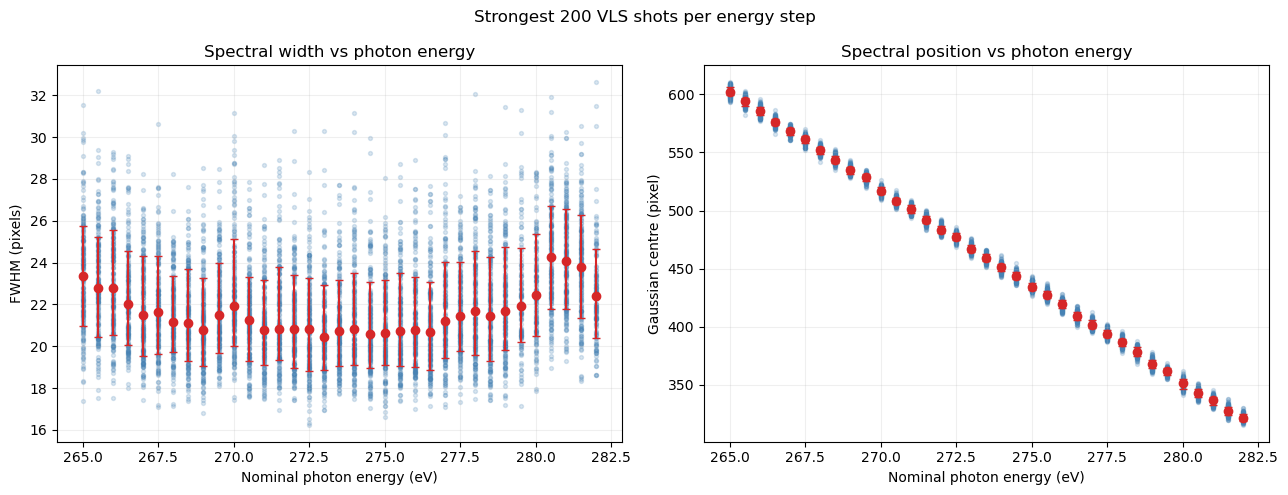

In [28]:
if any(fit_results.values()):
    # Gaussian width and centre vs photon energy

    fig, ax = plt.subplots(1, 2, figsize=(13, 5))

    for E, results in fit_results.items():

        if not len(results):
            continue

        for a, key in zip(ax, ["fwhm", "centre"]):

            values = np.array([r[key] for r in results])

            q16, median, q84 = np.percentile(values, [16, 50, 84])

            a.scatter(
                np.full(len(values), E), values,
                s=8, alpha=0.2, color="steelblue"
            )

            a.errorbar(
                E, median,
                yerr=[[median - q16], [q84 - median]],
                fmt="o", capsize=3, color="C3"
            )

    ax[0].set_ylabel("FWHM (pixels)")
    ax[0].set_title("Spectral width vs photon energy")

    ax[1].set_ylabel("Gaussian centre (pixel)")
    ax[1].set_title("Spectral position vs photon energy")

    for a in ax:
        a.set_xlabel("Nominal photon energy (eV)")
        a.grid(alpha=0.2)

    fig.suptitle(f"Strongest {N_STRONGEST} VLS shots per energy step")

    plt.tight_layout()
    plt.show()
else:
    print("No accepted Gaussian fits to plot")

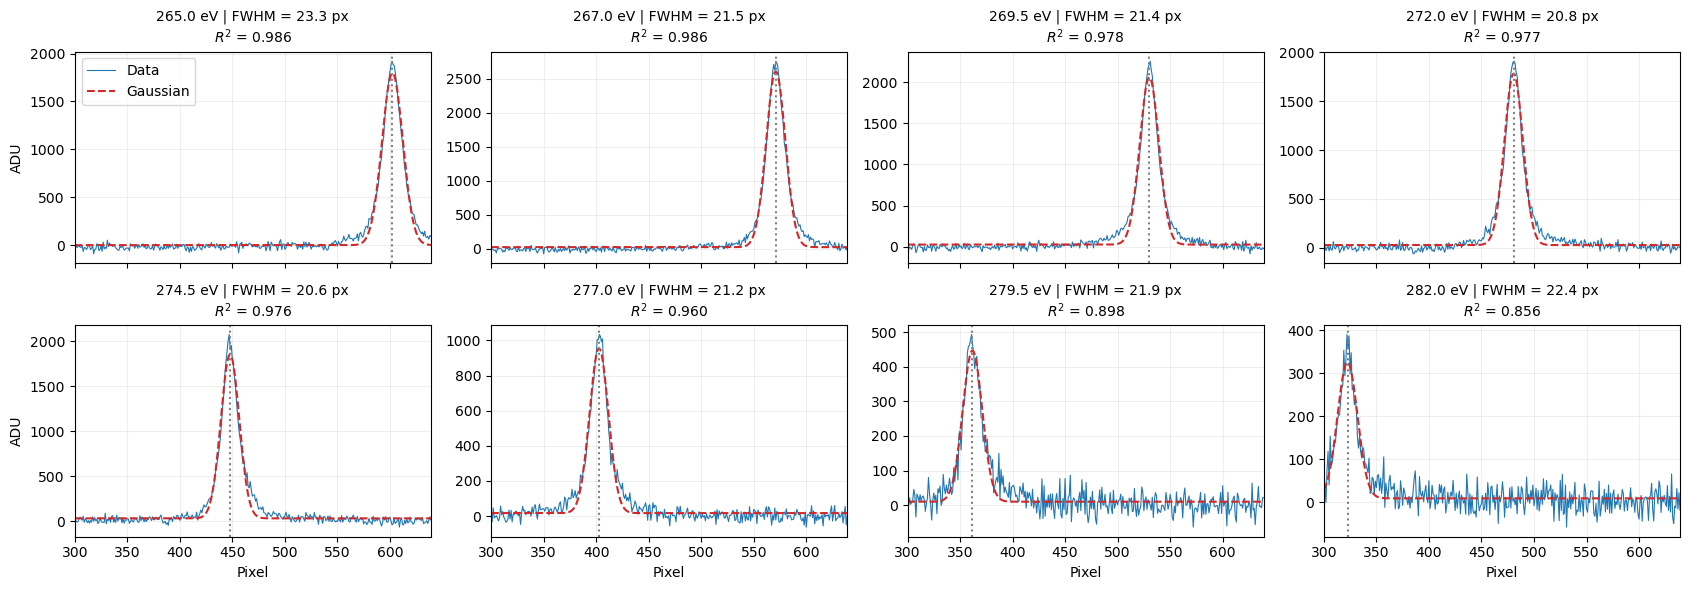

In [29]:
if any(fit_results.values()):
    # Inspect representative Gaussian fits

    available = [E for E in energies if len(fit_results[E])]

    if not available:
        raise ValueError("No accepted Gaussian fits")

    example_energies = np.array(available)[
        np.linspace(0, len(available)-1, min(8, len(available)), dtype=int)
    ]

    fig, axs = plt.subplots(2, 4, figsize=(17, 6), sharex=True)

    for ax, E in zip(axs.flat, example_energies):

        results = fit_results[E]

        # Select the shot closest to the median width
        widths = np.array([r["fwhm"] for r in results])
        result = results[np.argmin(np.abs(widths - np.median(widths)))]

        i = result["shot"]

        ax.plot(x, S[i], lw=0.8, label="Data")
        ax.plot(x, gaussian(x, *result["popt"]),
                color="C3", ls="--", label="Gaussian")

        ax.axvline(result["centre"], color="grey", ls=":")

        ax.set_title(
            f"{E:.1f} eV | FWHM = {result['fwhm']:.1f} px\n"
            f"$R^2$ = {result['r2']:.3f}",
            fontsize=10
        )

        ax.set_xlim(x[0], x[-1])
        ax.grid(alpha=0.2)

    for ax in axs.flat[len(example_energies):]:
        ax.set_visible(False)

    for ax in axs[1]:
        ax.set_xlabel("Pixel")

    for ax in axs[:, 0]:
        ax.set_ylabel("ADU")

    axs[0, 0].legend()

    plt.tight_layout()
    plt.show()
else:
    print("No accepted Gaussian fits to plot")

## 8. Optional: Gotthard / GMD bunch alignment

Set `CHECK_ALIGNMENT = True` to reload a small raw subset with zero offset, inspect raw and corrected spectra, and scan the correlation as a function of the line offset. The correlation removes mean train and bunch-position trends. Use the result as a diagnostic rather than automatically changing the offset; rerun from section 1 if the offset is changed.
This is the original alignment diagnostic (pedestal and common mode only), so the saved r = 0.946 can be compared directly; it does not apply the additional train-wise correction.

Loading 1 raw H5 file(s) for run 60545 (config 1).
  reading FLASH2_USER1_main_run60545_file1_20261124T165851.1.h5
Loaded 224 trains x 101 bunches (+ VLS, line b+0 -> bunch b).


/tmp/ipykernel_1125046/1000266614.py:26: RuntimeWarning: Mean of empty slice
  pedestal = np.nanmean(vls_raw[dark], axis=0)


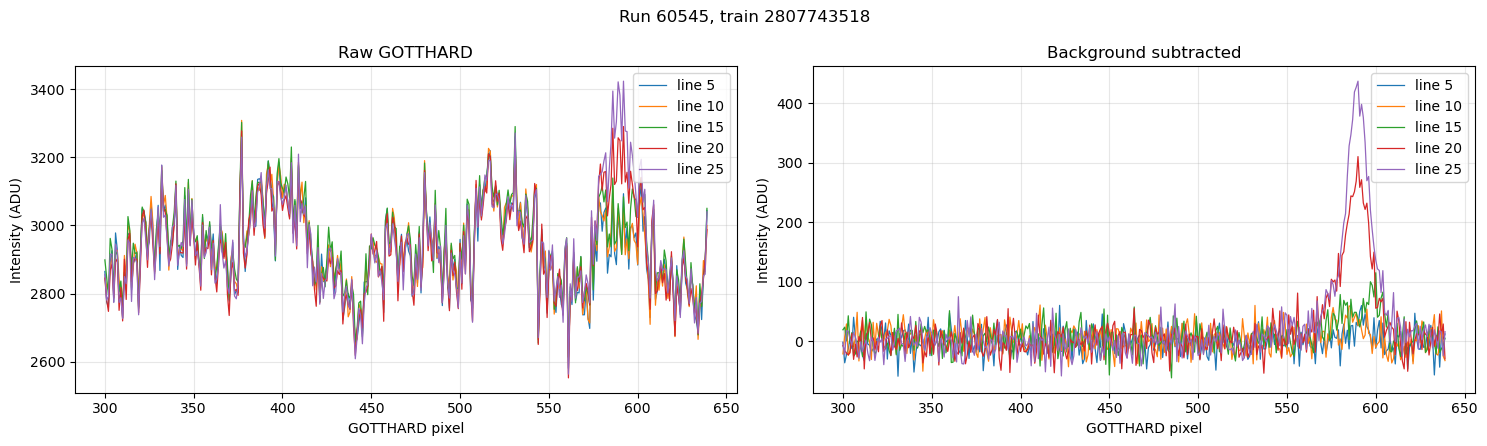

In [31]:
CHECK_ALIGNMENT = True

if CHECK_ALIGNMENT:
    # ---- Raw GOTTHARD spectra and background subtraction ------------------------
    ALIGN_RUN = RUN
    ALIGN_MAX_FILES = 1
    ALIGN_TRAIN_STEP = 20
    ALIGN_TRAIN = 0                # Index within the loaded train sample
    ALIGN_LINES = [5, 10, 15, 20, 25]  # Raw GOTTHARD line indices

    # Load with zero offset to preserve the original line indices
    align_data = data_loading.load_raw_h5(
        ALIGN_RUN, config=1, max_files=ALIGN_MAX_FILES,
        train_step=ALIGN_TRAIN_STEP, vls_offset=0,
    )

    gmd_align = align_data.gmd
    vls_raw = align_data.vls
    vls_raw[..., VLS_BAD_PIXELS] = np.nan

    # Original pedestal and common-mode subtraction for the offset diagnostic
    has_frame = np.isfinite(vls_raw[:, :, VLS_BG_PIXELS[0]])
    dark = has_frame & ~np.isfinite(gmd_align)

    if dark.sum() > 100:
        pedestal = np.nanmean(vls_raw[dark], axis=0)
    else:
        pedestal = np.zeros(vls_raw.shape[-1])
        print("WARNING: no dark frames, common mode only")

    cm = np.nanmedian(vls_raw[..., slice(*VLS_BG_PIXELS)] -
                      pedestal[slice(*VLS_BG_PIXELS)], axis=-1)

    processed = (vls_raw[..., slice(*VLS_ROI)] -
                 pedestal[slice(*VLS_ROI)] - cm[..., None])

    vls_int = np.nansum(processed, axis=-1)
    vls_int[~has_frame] = np.nan

    px = np.arange(*VLS_ROI)
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharex=True)

    for line in ALIGN_LINES:
        if not 0 <= line < vls_raw.shape[1]:
            continue
        axes[0].plot(px, vls_raw[ALIGN_TRAIN, line, slice(*VLS_ROI)], lw=0.9, label=f"line {line}")
        axes[1].plot(px, processed[ALIGN_TRAIN, line], lw=0.9, label=f"line {line}")

    axes[0].set_title("Raw GOTTHARD")
    axes[1].set_title("Background subtracted")

    for ax in axes:
        ax.set_xlabel("GOTTHARD pixel")
        ax.set_ylabel("Intensity (ADU)")
        ax.legend()
        ax.grid(alpha=0.3)

    fig.suptitle(f"Run {ALIGN_RUN}, train {int(align_data.tID[ALIGN_TRAIN])}")
    fig.tight_layout()
    plt.show()

    del align_data, vls_raw, processed
else:
    print("Alignment check skipped")

Highest correlation at VLS_OFFSET = 2
Correlation = 0.946


/tmp/ipykernel_1125046/1536826072.py:19: RuntimeWarning: Mean of empty slice
  g = g - np.nanmean(g, axis=0) - np.nanmean(g, axis=1, keepdims=True)
/tmp/ipykernel_1125046/1536826072.py:20: RuntimeWarning: Mean of empty slice
  v = v - np.nanmean(v, axis=0) - np.nanmean(v, axis=1, keepdims=True)
/tmp/ipykernel_1125046/1536826072.py:41: RuntimeWarning: Mean of empty slice
  g_mean = np.nanmean(gmd_align, axis=0)


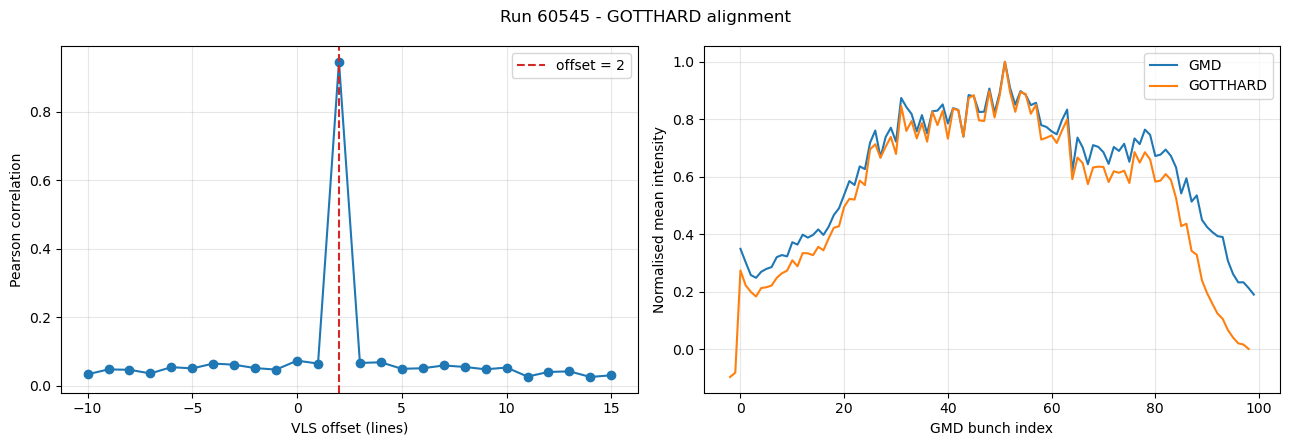

In [32]:
if CHECK_ALIGNMENT:
    # ---- GOTTHARD / GMD bunch alignment -----------------------------------------
    OFFSETS = np.arange(-10, 16)
    correlations = np.full(len(OFFSETS), np.nan)

    for k, offset in enumerate(OFFSETS):
        bunch = np.arange(gmd_align.shape[1])
        line = bunch + offset
        valid_lines = (line >= 0) & (line < vls_int.shape[1])

        g = gmd_align[:, bunch[valid_lines]]
        v = vls_int[:, line[valid_lines]]

        valid = np.isfinite(g) & np.isfinite(v) & (g > 0)
        g = np.where(valid, g, np.nan)
        v = np.where(valid, v, np.nan)

        # Remove average train and bunch-position dependence
        g = g - np.nanmean(g, axis=0) - np.nanmean(g, axis=1, keepdims=True)
        v = v - np.nanmean(v, axis=0) - np.nanmean(v, axis=1, keepdims=True)

        valid = np.isfinite(g) & np.isfinite(v)
        if valid.sum() > 10:
            correlations[k] = np.corrcoef(g[valid], v[valid])[0, 1]

    if not np.isfinite(correlations).any():
        raise ValueError("No finite offset correlations")
    best_offset = int(OFFSETS[np.nanargmax(correlations)])
    print(f"Highest correlation at VLS_OFFSET = {best_offset}")
    print(f"Correlation = {np.nanmax(correlations):.3f}")

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    axes[0].plot(OFFSETS, correlations, "o-")
    axes[0].axvline(best_offset, color="C3", ls="--", label=f"offset = {best_offset}")
    axes[0].set(xlabel="VLS offset (lines)", ylabel="Pearson correlation")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # Compare average pulse profiles after applying the selected offset
    g_mean = np.nanmean(gmd_align, axis=0)
    v_mean = np.nanmean(vls_int, axis=0)

    axes[1].plot(np.arange(len(g_mean)), g_mean / np.nanmax(g_mean), label="GMD")
    axes[1].plot(np.arange(len(v_mean)) - best_offset,
                 v_mean / np.nanmax(v_mean), label="GOTTHARD")
    axes[1].set(xlabel="GMD bunch index", ylabel="Normalised mean intensity")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    fig.suptitle(f"Run {ALIGN_RUN} - GOTTHARD alignment")
    fig.tight_layout()
    plt.show()